<a href="https://colab.research.google.com/github/sarthakpanwar1307-hub/Skill_Bridge/blob/main/SkillBridge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
# Creating SkillBridge Skill Database

skills_data = {
    "skill_id": [
        "S001",
        "S002",
        "S003",
        "S004",
        "S005",
        "S006",
        "S007",
        "S008",
        "S009",
        "S010"
    ],

    "skill_name": [
        "Python",
        "SQL",
        "Machine Learning",
        "Pandas",
        "NumPy",
        "Statistics",
        "TensorFlow",
        "PyTorch",
        "Power BI",
        "Excel"
    ],

    "category": [
        "Programming",
        "Database",
        "Artificial Intelligence",
        "Data Analysis",
        "Data Analysis",
        "Mathematics",
        "Deep Learning",
        "Deep Learning",
        "Visualization",
        "Data Analysis"
    ]
}

skills_df = pd.DataFrame(skills_data)

skills_df.to_csv("skills.csv", index=False)

import os
os.listdir()

skills_test = pd.read_csv("skills.csv")

,skill_id,skill_name,category
0,S001,Python,Programming
1,S002,SQL,Database
2,S003,Machine Learning,Artificial Intelligence
3,S004,Pandas,Data Analysis
4,S005,NumPy,Data Analysis
5,S006,Statistics,Mathematics
6,S007,TensorFlow,Deep Learning
7,S008,PyTorch,Deep Learning
8,S009,Power BI,Visualization
9,S010,Excel,Data Analysis


In [6]:
# Creating SkillBridge Career Database

careers_data = {
    "career_id": [
        "C001",
        "C002",
        "C003",
        "C004",
        "C005"
    ],

    "career_role": [
        "Data Analyst",
        "Data Scientist",
        "Machine Learning Engineer",
        "Data Engineer",
        "Business Intelligence Analyst"
    ],

    "required_skills": [
        "Python, SQL, Excel, Power BI",
        "Python, SQL, Statistics, Machine Learning",
        "Python, Machine Learning, TensorFlow, PyTorch",
        "Python, SQL, Databases, Cloud",
        "SQL, Excel, Power BI, Data Visualization"
    ],

    "career_category": [
        "Data Analytics",
        "Artificial Intelligence",
        "Artificial Intelligence",
        "Data Engineering",
        "Business Analytics"
    ]
}

careers_df = pd.DataFrame(careers_data)

careers_df.to_csv("careers.csv", index=False)


In [8]:
# Creating Skill-Career Relationship Dataset

mapping_data = {
    "career_role": [
        "Data Analyst",
        "Data Analyst",
        "Data Analyst",
        "Data Analyst",

        "Data Scientist",
        "Data Scientist",
        "Data Scientist",
        "Data Scientist",

        "Machine Learning Engineer",
        "Machine Learning Engineer",
        "Machine Learning Engineer",
        "Machine Learning Engineer"
    ],

    "skill_name": [
        "Python",
        "SQL",
        "Excel",
        "Power BI",

        "Python",
        "SQL",
        "Statistics",
        "Machine Learning",

        "Python",
        "Machine Learning",
        "TensorFlow",
        "PyTorch"
    ],

    "importance": [
        "High",
        "High",
        "Medium",
        "Medium",

        "High",
        "High",
        "High",
        "High",

        "High",
        "High",
        "Medium",
        "Medium"
    ]
}

skill_career_df = pd.DataFrame(mapping_data)
skill_career_df.to_csv("skill_career_mapping.csv", index=False)


In [9]:
!pip install networkx
import networkx as nx
import matplotlib.pyplot as plt

In [10]:
G = nx.Graph()

for index, row in skill_career_df.iterrows():

    career = row["career_role"]
    skill = row["skill_name"]

    G.add_node(career, type="career")
    G.add_node(skill, type="skill")

    G.add_edge(skill, career, relationship="required_for")
print("Number of Nodes:", G.number_of_nodes())
print("Number of Connections:", G.number_of_edges())

Number of Nodes: 11
Number of Connections: 12


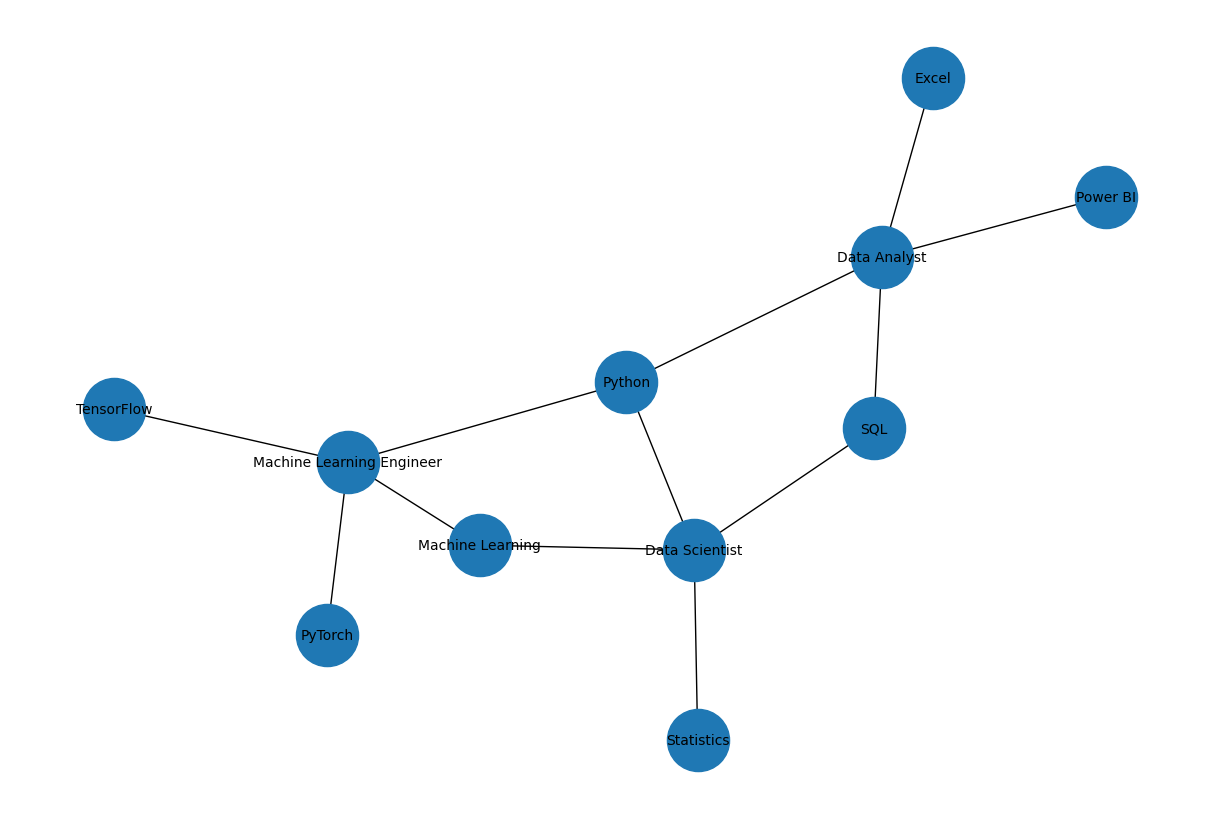

In [11]:
plt.figure(figsize=(12,8))

pos = nx.spring_layout(G)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=2000,
    font_size=10
)

plt.show()

In [13]:
students_data = {
    "student_id": [
        "ST001",
        "ST002",
        "ST003"
    ],

    "student_name": [
        "Student_A",
        "Student_B",
        "Student_C"
    ],

    "skills": [
        "Python, SQL, Pandas",
        "Python, Statistics, Machine Learning",
        "SQL, Excel, Power BI"
    ],

    "education": [
        "B.Tech Computer Science",
        "B.Tech Data Science",
        "B.Tech Computer Science"
    ]
}

students_df = pd.DataFrame(students_data)

students_df.to_csv("students.csv", index=False)


In [14]:
def calculate_skill_match(student_skills, career_skills):

    student_skills = set(student_skills.split(", "))
    career_skills = set(career_skills.split(", "))

    matched = student_skills.intersection(career_skills)
    missing = career_skills.difference(student_skills)

    score = (len(matched) / len(career_skills)) * 100

    return matched, missing, round(score, 2)

In [17]:
def recommend_careers(student_skills, careers_df):

    results = []

    for index, career in careers_df.iterrows():

        matched, missing, score = calculate_skill_match(
            student_skills,
            career["required_skills"]
        )

        results.append({
            "Career": career["career_role"],
            "Match Score": score,
            "Matched Skills": ", ".join(matched),
            "Missing Skills": ", ".join(missing)
        })

    recommendation_df = pd.DataFrame(results)

    return recommendation_df.sort_values(
        by="Match Score",
        ascending=False
    )

In [18]:
student = students_df.iloc[0]

recommendations = recommend_careers(
    student["skills"],
    careers_df
)

recommendations

,Career,Match Score,Matched Skills,Missing Skills
0,Data Analyst,50.0,"Python, SQL","Power BI, Excel"
1,Data Scientist,50.0,"Python, SQL","Machine Learning, Statistics"
3,Data Engineer,50.0,"Python, SQL","Cloud, Databases"
2,Machine Learning Engineer,25.0,Python,"Machine Learning, TensorFlow, PyTorch"
4,Business Intelligence Analyst,25.0,SQL,"Excel, Power BI, Data Visualization"


In [20]:
# Expanding SkillBridge Skill Database

skills_list = [

    # Programming
    ("S001","Python","Programming"),
    ("S002","Java","Programming"),
    ("S003","C++","Programming"),
    ("S004","JavaScript","Programming"),
    ("S005","R","Programming"),
    ("S006","SQL","Database"),

    # Data Science
    ("S007","Machine Learning","Artificial Intelligence"),
    ("S008","Deep Learning","Artificial Intelligence"),
    ("S009","Statistics","Mathematics"),
    ("S010","Data Analysis","Data Science"),
    ("S011","Feature Engineering","Data Science"),
    ("S012","Model Evaluation","Data Science"),
    ("S013","Predictive Modeling","Data Science"),

    # Python Tools
    ("S014","Pandas","Data Analysis"),
    ("S015","NumPy","Data Analysis"),
    ("S016","Scikit-learn","Machine Learning"),
    ("S017","TensorFlow","Deep Learning"),
    ("S018","PyTorch","Deep Learning"),
    ("S019","Matplotlib","Visualization"),
    ("S020","Seaborn","Visualization"),

    # Databases
    ("S021","MySQL","Database"),
    ("S022","PostgreSQL","Database"),
    ("S023","MongoDB","Database"),
    ("S024","Data Warehousing","Database"),

    # Cloud
    ("S025","AWS","Cloud"),
    ("S026","Azure","Cloud"),
    ("S027","Google Cloud","Cloud"),
    ("S028","Docker","Deployment"),
    ("S029","Kubernetes","Deployment"),

    # AI
    ("S030","Natural Language Processing","AI"),
    ("S031","Computer Vision","AI"),
    ("S032","Generative AI","AI"),
    ("S033","Large Language Models","AI"),
    ("S034","Prompt Engineering","AI"),
    ("S035","RAG","AI"),

    # Software
    ("S036","Data Structures","Computer Science"),
    ("S037","Algorithms","Computer Science"),
    ("S038","Git","Development"),
    ("S039","GitHub","Development"),
    ("S040","REST API","Development"),
    ("S041","FastAPI","Development"),

    # Business
    ("S042","Power BI","Visualization"),
    ("S043","Tableau","Visualization"),
    ("S044","Excel","Data Analysis"),
    ("S045","Business Intelligence","Analytics"),
    ("S046","Dashboard Design","Analytics")
]


skills_df = pd.DataFrame(
    skills_list,
    columns=["skill_id","skill_name","category"]
)

skills_df.head()
skills_df.to_csv("skills.csv", index=False)


In [23]:
# Expanding SkillBridge Career Database

careers_data = [

    ("C001", "Data Analyst", "Python, SQL, Excel, Power BI, Data Analysis"),
    ("C002", "Data Scientist", "Python, SQL, Statistics, Machine Learning, Pandas"),
    ("C003", "Machine Learning Engineer", "Python, Machine Learning, TensorFlow, PyTorch"),
    ("C004", "Data Engineer", "Python, SQL, Data Warehousing, Cloud, Databases"),
    ("C005", "Business Intelligence Analyst", "SQL, Excel, Power BI, Tableau"),

    ("C006", "AI Engineer", "Python, Deep Learning, Machine Learning, Generative AI"),
    ("C007", "NLP Engineer", "Python, NLP, Machine Learning, Large Language Models"),
    ("C008", "Computer Vision Engineer", "Python, Computer Vision, Deep Learning"),

    ("C009", "Software Developer", "C++, Java, Data Structures, Algorithms, Git"),
    ("C010", "Backend Developer", "Python, Java, REST API, FastAPI, SQL"),

    ("C011", "Cloud Engineer", "AWS, Azure, Docker, Kubernetes"),
    ("C012", "DevOps Engineer", "Docker, Kubernetes, Cloud, CI/CD"),

    ("C013", "Database Administrator", "SQL, MySQL, PostgreSQL, Database Design"),
    ("C014", "Data Architect", "Data Warehousing, Cloud, Databases, SQL"),

    ("C015", "Research Scientist", "Python, Statistics, Machine Learning, Deep Learning"),
    ("C016", "BI Developer", "SQL, Power BI, Tableau, Dashboard Design"),

    ("C017", "AI Product Engineer", "Python, Generative AI, APIs, Large Language Models"),
    ("C018", "Data Visualization Specialist", "Power BI, Tableau, Excel, Data Storytelling"),

    ("C019", "Cybersecurity Analyst", "Python, Networking, Security, Linux"),
    ("C020", "Full Stack Developer", "JavaScript, Python, REST API, Databases")
]


careers_df = pd.DataFrame(
    careers_data,
    columns=["career_id", "career_role", "required_skills"]
)

careers_df.head()
careers_df.to_csv("careers.csv", index=False)
print("Total Careers:", len(careers_df))

Total Careers: 20


In [24]:
# Creating updated skill-career mapping

mapping = []

for index, row in careers_df.iterrows():

    career = row["career_role"]
    skills = row["required_skills"].split(", ")

    for skill in skills:
        mapping.append(
            [career, skill]
        )

skill_career_df = pd.DataFrame(
    mapping,
    columns=["career_role", "skill_name"]
)

skill_career_df.head()
print("Total Skill-Career Connections:", len(skill_career_df))
skill_career_df.to_csv("skill_career_mapping.csv", index=False)


Total Skill-Career Connections: 84


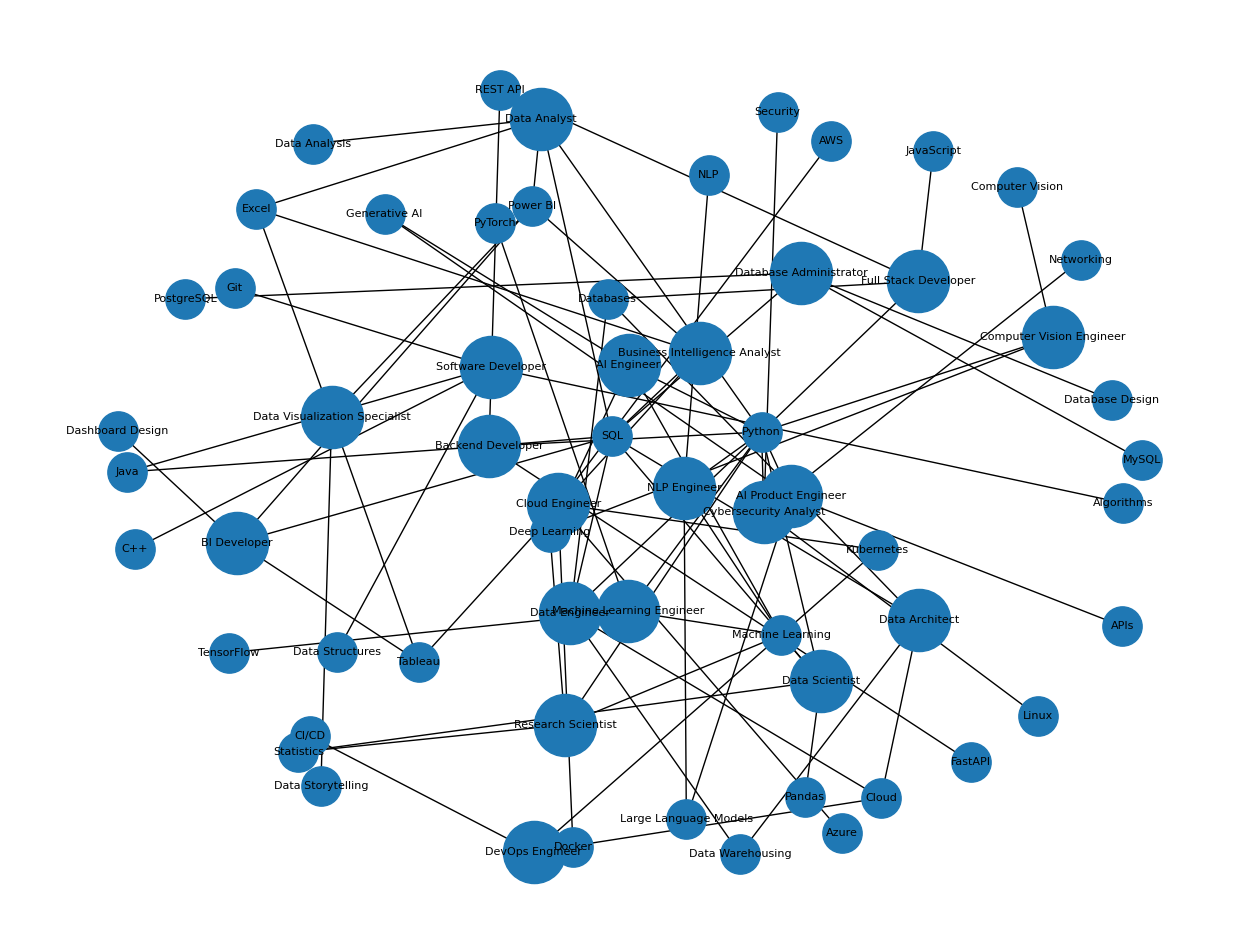

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16,12))

pos = nx.spring_layout(G, seed=42, k=1)

career_nodes = [
    node for node, data in G.nodes(data=True)
    if data["type"] == "career"
]

skill_nodes = [
    node for node, data in G.nodes(data=True)
    if data["type"] == "skill"
]

nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=career_nodes,
    node_size=2000
)

nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=skill_nodes,
    node_size=800
)

nx.draw_networkx_edges(
    G,
    pos
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=8
)

plt.axis("off")
plt.show()